# EDA · RWB «Отгрузки без простоев»

Задача: для каждого из **1000 маршрутов** предсказать `target_1h` (объём, отгруженный за последний час) на **8 получасовых шагов вперёд** — 01.11.2025, 11:00–14:30.

> **Главный вывод.** Каждый маршрут — это свой уровень плюс сильный шум (типичное отклонение ≈ 48 % от среднего). Сезонность слабая, а прошлые значения почти ничего не говорят о будущем дальше чем на 30 минут. Поэтому точность прогноза в первую очередь зависит от того, **насколько точно мы оценим текущий уровень маршрута**. Простое среднее за последнюю неделю уже даёт **WAPE 0.34** — это планка для моделей.

| | |
|---|---|
| Данные | 1000 маршрутов × 4630 точек с шагом 30 мин, 28.07 → 01.11.2025 10:30, без пропусков |
| Test | следующие 8 шагов после train, только `id`, `route_id`, `timestamp` |
| Шум | отклонение от среднего маршрута ≈ 48 %; связь только с соседней точкой (0.48) |
| Тренд и сезонность | рост ≈ 30 % с августа по октябрь; сутки −13…+7 %, день недели −4…+3 % |
| Статусы | опережают таргет на 1–4 шага, но в test их нет — помогут только первым шагам |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates

DATA = Path('..') / 'data'

# Палитра и оформление графиков
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'font.size': 10,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK2, 'ytick.color': INK2, 'xtick.major.size': 0, 'ytick.major.size': 0,
    'lines.linewidth': 2, 'axes.axisbelow': True, 'legend.frameon': False, 'legend.labelcolor': INK2,
})
pd.set_option('display.float_format', '{:,.3f}'.format)
millions = mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f} млн')
thousands = mticker.FuncFormatter(lambda x, _: f'{x/1e3:,.0f} тыс'.replace(',', ' '))

## 1. Структура данных

In [2]:
train = pd.read_parquet(DATA / 'train_solo_track.parquet').sort_values(['route_id', 'timestamp'], ignore_index=True)
test = pd.read_parquet(DATA / 'test_solo_track.parquet')
STATUS = [f'status_{i}' for i in range(1, 7)]

n_routes, n_steps = train.route_id.nunique(), train.groupby('route_id').size().iloc[0]
summary = pd.Series({
    'train: строк': f'{len(train):,}',
    'train: маршрутов': n_routes,
    'train: точек на маршрут': n_steps,
    'train: период': f'{train.timestamp.min():%d.%m.%Y %H:%M} → {train.timestamp.max():%d.%m.%Y %H:%M}',
    'шаг времени': ', '.join(map(str, train.groupby('route_id').timestamp.diff().dropna().unique())),
    'пропуски (NaN)': int(train.isna().sum().sum()),
    'полная сетка маршрут × время': len(train) == n_routes * n_steps,
    'test: строк': f'{len(test):,}',
    'test: колонки': ', '.join(test.columns),
    'test: окно': f'{test.timestamp.min():%d.%m.%Y %H:%M} → {test.timestamp.max():%H:%M} ({test.timestamp.nunique()} шагов, суббота)',
    'test: те же маршруты': set(test.route_id) == set(train.route_id),
}, name='значение')
summary.to_frame()

,значение
train: строк,"4,630,000"
train: маршрутов,1000
train: точек на маршрут,4630
train: период,28.07.2025 00:00 → 01.11.2025 10:30
шаг времени,0 days 00:30:00
пропуски (NaN),0
полная сетка маршрут × время,True
test: строк,"8,000"
test: колонки,"id, route_id, timestamp"
test: окно,"01.11.2025 11:00 → 14:30 (8 шагов, суббота)"


In [3]:
train.head(6)

,route_id,timestamp,status_1,status_2,status_3,status_4,status_5,status_6,target_1h
0,0,2025-07-28 00:00:00,13,13,7,58053,136443,97,87359
1,0,2025-07-28 00:30:00,6,18,13,58867,134643,95,182291
2,0,2025-07-28 01:00:00,7,8,27,54848,135534,96,271432
3,0,2025-07-28 01:30:00,7,8,5,53086,136497,100,169736
4,0,2025-07-28 02:00:00,1,6,0,57561,135314,101,38880
5,0,2025-07-28 02:30:00,10,18,11,55368,134059,98,134137


Сетка полная, поэтому дальше таргет и статусы считаем как матрицы **маршрут × время** (1000 × 4630).

In [4]:
Y = train.target_1h.to_numpy(dtype=np.float64).reshape(n_routes, n_steps)
times = train.timestamp.iloc[:n_steps].reset_index(drop=True)
S = {c: train[c].to_numpy(dtype=np.float64).reshape(n_routes, n_steps) for c in STATUS}

## 2. Целевая переменная

In [5]:
t = train.target_1h
route_mean = Y.mean(1)
pd.Series({
    'медиана': f'{t.median():,.0f}',
    'среднее': f'{t.mean():,.0f}',
    '99-й перцентиль': f'{t.quantile(.99):,.0f}',
    'максимум': f'{t.max():,.0f}',
    'доля нулей': f'{(t == 0).mean():.1%}',
    'разброс внутри маршрута (std / среднее, медиана)': f'{np.median(Y.std(1) / Y.mean(1)):.0%}',
    'точек > 5 × медианы маршрута': f'{(Y > 5 * np.median(Y, 1, keepdims=True)).mean():.2%}',
    'среднее по маршрутам: min / медиана / max': f'{route_mean.min():,.0f} / {np.median(route_mean):,.0f} / {route_mean.max():,.0f}',
}, name='target_1h').to_frame()

,target_1h
медиана,"235,769"
среднее,"261,242"
99-й перцентиль,"743,427"
максимум,"10,831,337"
доля нулей,1.5%
"разброс внутри маршрута (std / среднее, медиана)",48%
точек > 5 × медианы маршрута,0.05%
среднее по маршрутам: min / медиана / max,"50,752 / 258,177 / 981,152"


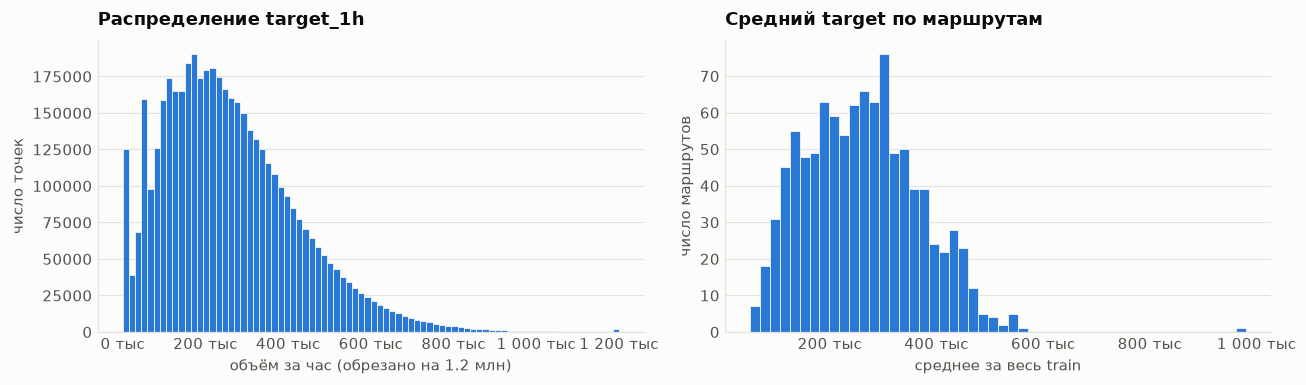

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6))
a1.hist(t.clip(upper=1.2e6), bins=80, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
a1.set_title('Распределение target_1h')
a1.xaxis.set_major_formatter(thousands); a1.set_xlabel('объём за час (обрезано на 1.2 млн)')
a2.hist(route_mean, bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
a2.set_title('Средний target по маршрутам')
a2.xaxis.set_major_formatter(thousands); a2.set_xlabel('среднее за весь train')
for a in (a1, a2): a.set_ylabel('число точек' if a is a1 else 'число маршрутов')
plt.tight_layout()

In [7]:
# Где нули и выбросы
zeros = train[train.target_1h == 0]
top_zero_slots = zeros.timestamp.dt.strftime('%H:%M').value_counts().head(5)
top_outlier_routes = (train.assign(r=train.target_1h / train.groupby('route_id').target_1h.transform('median'))
                      .query('r > 5').route_id.value_counts().head(5))
pd.concat({'нули: топ времени суток': top_zero_slots.reset_index(drop=False).astype(str).agg(' — '.join, axis=1),
           'выбросы > 5× медианы: топ маршрутов': top_outlier_routes.reset_index().astype(str).agg(' — '.join, axis=1)}, axis=1)

,нули: топ времени суток,выбросы > 5× медианы: топ маршрутов
0,21:00 — 2126,417 — 350
1,21:30 — 2093,853 — 209
2,20:30 — 1979,702 — 121
3,09:00 — 1958,50 — 112
4,09:30 — 1882,192 — 82


- **Шум большой:** типичное отклонение точки от среднего своего маршрута ≈ 48 %.
- **Маршруты разного масштаба:** средние от 50 тыс до 980 тыс, разница примерно в 20 раз. Модель лучше учить на таргете, нормированном на уровень маршрута.
- **Нули** (1.5 %) в основном около 9:00 и 21:00 — похоже на пересменки — и чаще в первые недели.
- **Выбросы** (> 5× медианы маршрута) — 0.05 % точек, сосредоточены в нескольких маршрутах (417, 853, 702, 50). При обучении их стоит обрезать.

## 3. Динамика во времени

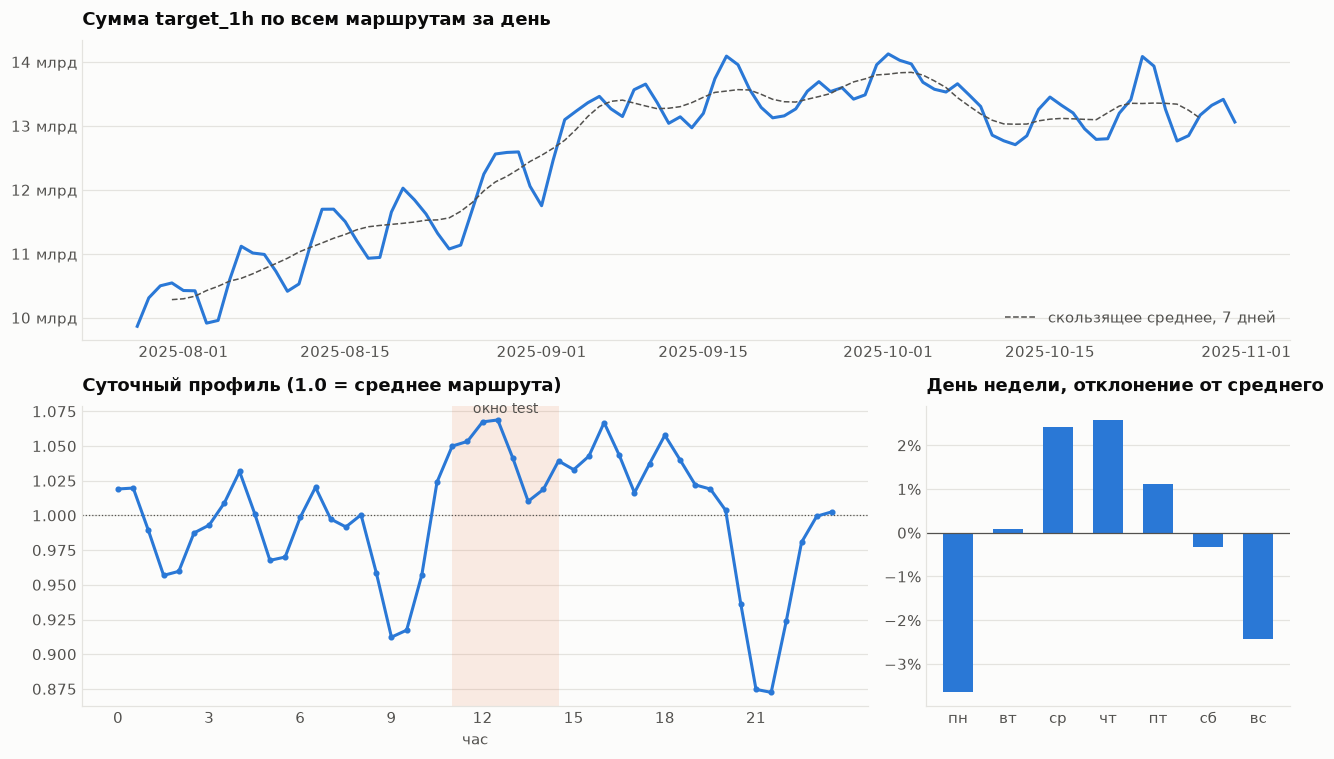

In [8]:
daily = train.assign(date=train.timestamp.dt.normalize()).groupby('date').target_1h.sum()
daily = daily.iloc[:-1]  # последний день неполный (до 10:30)
norm = Y / Y.mean(1, keepdims=True)
slot_prof = pd.Series(norm.mean(0)).groupby((times.dt.hour + times.dt.minute / 60).to_numpy()).mean()
dow_prof = pd.Series(norm.mean(0)).groupby(times.dt.day_of_week.to_numpy()).mean()

fig = plt.figure(figsize=(12, 7))
g = fig.add_gridspec(2, 3)
a = fig.add_subplot(g[0, :])
a.plot(daily.index, daily.values, color=BLUE)
a.plot(daily.index, daily.rolling(7, center=True).mean(), color=INK2, linewidth=1, linestyle='--', label='скользящее среднее, 7 дней')
a.set_title('Сумма target_1h по всем маршрутам за день'); a.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e9:.0f} млрд'))
a.legend(loc='lower right')

b = fig.add_subplot(g[1, :2])
b.axvspan(11, 14.5, color=ORANGE, alpha=0.12, linewidth=0)
b.text(12.75, slot_prof.max() + 0.005, 'окно test', ha='center', color=INK2, fontsize=9)
b.axhline(1, color=INK2, linewidth=0.8, linestyle=':')
b.plot(slot_prof.index, slot_prof.values, color=BLUE, marker='o', markersize=3)
b.set_title('Суточный профиль (1.0 = среднее маршрута)'); b.set_xticks(range(0, 24, 3)); b.set_xlabel('час')

c = fig.add_subplot(g[1, 2])
c.bar(['пн', 'вт', 'ср', 'чт', 'пт', 'сб', 'вс'], dow_prof.values - 1, color=BLUE, width=0.6)
c.axhline(0, color=INK2, linewidth=0.8)
c.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
c.set_title('День недели, отклонение от среднего')
plt.tight_layout()

- **Тренд важнее сезонности.** С начала августа по конец сентября уровень вырос примерно на 30 %, в октябре вышел на плато. Свежая история важнее старой.
- **Сутки:** провалы около 9–10 и 21–22 ч. Окно test (11:00–14:30) чуть выше среднего (+4…7 %).
- **День недели:** −4…+3 %. Test приходится на субботу — день около среднего.

## 4. Как устроен ряд: автокорреляция

,лаг 1,лаг 2,лаг 3,лаг 4,лаг 8,лаг 48,лаг 96,лаг 336
корреляция,0.479,-0.017,0.032,0.066,0.126,0.169,0.155,0.138


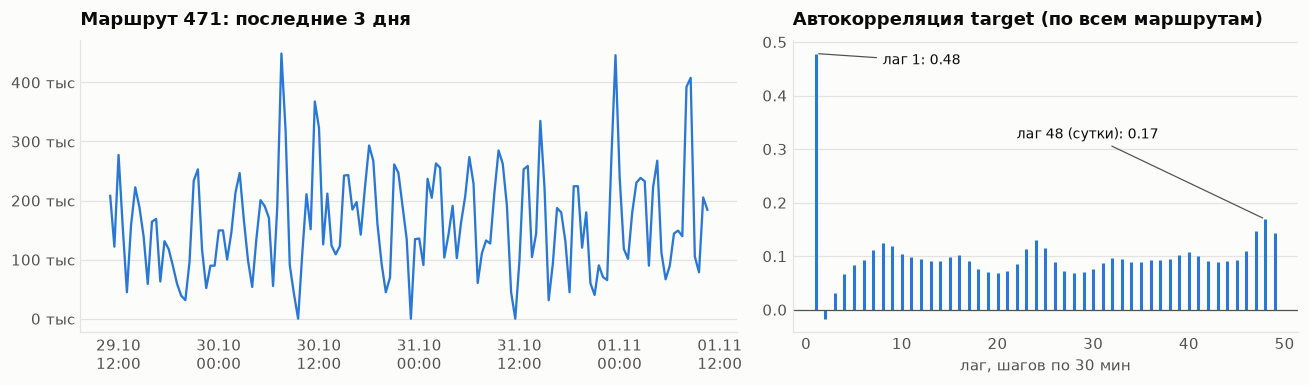

In [9]:
Yd = Y - Y.mean(1, keepdims=True)
def acf(X, lag):
    a, b = X[:, lag:].ravel(), X[:, :-lag].ravel()
    return np.corrcoef(a, b)[0, 1]
lags = np.arange(1, 50)
ac = pd.Series([acf(Yd, k) for k in lags], index=lags)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={'width_ratios': [1.3, 1]})
r = 471; w = slice(n_steps - 3 * 48, n_steps)
a1.plot(times[w], Y[r, w], color=BLUE, linewidth=1.5)
a1.set_title(f'Маршрут {r}: последние 3 дня'); a1.yaxis.set_major_formatter(thousands)
a1.tick_params(axis='x', labelrotation=0)
a1.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m\n%H:%M'))
a2.vlines(ac.index, 0, ac.values, color=BLUE, linewidth=2)
a2.axhline(0, color=INK2, linewidth=0.8)
a2.annotate(f'лаг 1: {ac[1]:.2f}', (1, ac[1]), xytext=(8, ac[1] - 0.02), color=INK, fontsize=9, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
a2.annotate(f'лаг 48 (сутки): {ac[48]:.2f}', (48, ac[48]), xytext=(22, 0.32), color=INK, fontsize=9, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
a2.set_title('Автокорреляция target (по всем маршрутам)'); a2.set_xlabel('лаг, шагов по 30 мин')
plt.tight_layout()
pd.Series({f'лаг {k}': acf(Yd, k) for k in [1, 2, 3, 4, 8, 48, 96, 336]}, name='корреляция').to_frame().T

**Связь есть только с соседней точкой:** корреляция 0.48, через одну — уже около 0.

Причина: `target_1h` — сумма за час, а точки идут каждые 30 минут. Соседние точки делят общий получас и поэтому похожи, а точки через одну уже не пересекаются. Значит, сами получасовые отгрузки почти не зависят друг от друга (в терминах моделей это MA(1)).

Для прогноза это значит: последнее значение (10:30) помогает только **первому** шагу test (11:00). Дальше остаётся уровень маршрута и слабая сезонность.

## 5. Статусы

In [10]:
lag_corr = pd.DataFrame({c: [np.corrcoef(Yd[:, k:].ravel(), (S[c] - S[c].mean(1, keepdims=True))[:, :n_steps - k].ravel())[0, 1]
                             for k in range(0, 9)] for c in STATUS}, index=pd.Index(range(9), name='лаг статуса'))
smooth = pd.Series({c: acf(S[c] - S[c].mean(1, keepdims=True), 1) for c in STATUS}, name='автокорр. лаг 1')
scale = train[STATUS].median().rename('медиана')
(pd.concat([scale, smooth], axis=1).T.style
 .format('{:,.0f}', subset=pd.IndexSlice['медиана', :])
 .format('{:.3f}', subset=pd.IndexSlice['автокорр. лаг 1', :]))

,status_1,status_2,status_3,status_4,status_5,status_6
медиана,21,21,19,"109,912","618,836",162
автокорр. лаг 1,0.397,0.383,-0.078,0.976,0.999,0.995


лаг статуса,0,1,2,3,4,5,6,7,8
status_1,0.086,0.110,0.153,0.190,0.196,0.177,0.155,0.140,0.128
status_2,0.105,0.157,0.263,0.271,0.215,0.173,0.152,0.138,0.122
status_3,0.224,0.393,0.164,0.031,0.027,0.039,0.046,0.050,0.059
status_4,0.126,0.128,0.128,0.126,0.124,0.123,0.122,0.121,0.121
status_5,0.130,0.133,0.135,0.136,0.136,0.136,0.137,0.137,0.137
status_6,0.042,0.042,0.042,0.042,0.042,0.042,0.042,0.042,0.042


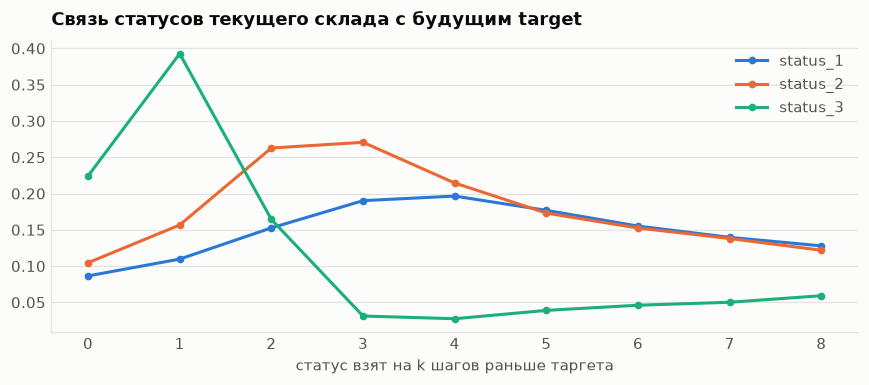

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for c, col in zip(['status_1', 'status_2', 'status_3'], [BLUE, ORANGE, AQUA]):
    ax.plot(lag_corr.index, lag_corr[c], color=col, marker='o', markersize=4, label=c)
ax.set_xlabel('статус взят на k шагов раньше таргета')
ax.set_title('Связь статусов текущего склада с будущим target')
ax.legend(loc='upper right')
plt.tight_layout()
lag_corr.T.round(3)

- **Текущий склад (`status_1…3`)** опережает таргет: `status_3` — на 1 шаг (корреляция 0.39), `status_2` — на 2–3, `status_1` — на 3–4. Похоже на путь товара по этапам перед отгрузкой.
- **Предыдущий склад (`status_4…6`)** — большие и очень гладкие ряды. С колебаниями таргета связаны слабо (~0.13) и одинаково на всех лагах, то есть скорее отражают уровень маршрута.
- **В test статусов нет**, известны только значения на 10:30. Поэтому статусы помогут только первым шагам прогноза.

## 6. Простые прогнозы

Повторяем условия test на истории: 12 раз обрезаем train в 10:30 (6 последних дней и 6 предыдущих суббот) и прогнозируем следующие 8 шагов.

Метрика соревнования не опубликована, поэтому главная метрика здесь — **WAPE**: сумма ошибок / сумма факта. Например, 0.34 значит, что ошибаемся на 34 % объёма. MAE и RMSE — для справки.

In [12]:
H, D = 8, 48
last = n_steps - 1                          # 01.11 10:30 — последняя точка train
cuts = sorted({last - D * d for d in range(1, 7)} | {last - 7 * D * k for k in range(1, 7)})  # все срезы в 10:30
rho = acf(Yd, 1)

def baselines(c):
    hist = lambda days: Y[:, c - D * days + 1:c + 1]
    preds = {f'среднее {d} дн.': np.repeat(hist(d).mean(1, keepdims=True), H, 1) for d in (1, 3, 7, 14, 28)}
    preds['медиана 7 дн.'] = np.repeat(np.median(hist(7), 1, keepdims=True), H, 1)
    preds['последнее значение'] = np.repeat(Y[:, [c]], H, 1)
    preds['маршрут × время суток, 14 дн.'] = np.stack([Y[:, [c + h - D * j for j in range(1, 15)]].mean(1) for h in range(1, H + 1)], 1)
    m7 = hist(7).mean(1)
    ar = np.repeat(m7[:, None], H, 1); ar[:, 0] = m7 + rho * (Y[:, c] - m7)
    preds['среднее 7 дн. + поправка 1-го шага'] = ar
    return preds

rows, per_h = [], {}
for c in cuts:
    fact = Y[:, c + 1:c + 1 + H]
    for name, p in baselines(c).items():
        e = np.abs(fact - p)
        rows.append({'бейзлайн': name, 'WAPE': e.sum() / fact.sum(), 'MAE': e.mean(), 'RMSE': np.sqrt(((fact - p) ** 2).mean())})
        per_h.setdefault(name, []).append(e.sum(0) / fact.sum(0))
res = pd.DataFrame(rows).groupby('бейзлайн').mean().sort_values('WAPE')
res.style.format({'WAPE': '{:.3f}', 'MAE': '{:,.0f}', 'RMSE': '{:,.0f}'}).background_gradient(subset=['WAPE'], cmap='Blues_r')

,WAPE,MAE,RMSE
бейзлайн,,,
среднее 7 дн. + поправка 1-го шага,0.336,"96,387","134,424"
среднее 3 дн.,0.339,"97,300","135,813"
среднее 7 дн.,0.340,"97,422","136,065"
медиана 7 дн.,0.340,"97,562","137,908"
среднее 1 дн.,0.341,"97,660","136,548"
среднее 14 дн.,0.342,"97,956","136,760"
среднее 28 дн.,0.345,"99,000","138,700"
"маршрут × время суток, 14 дн.",0.354,"101,342","139,365"
последнее значение,0.472,"135,386","194,574"


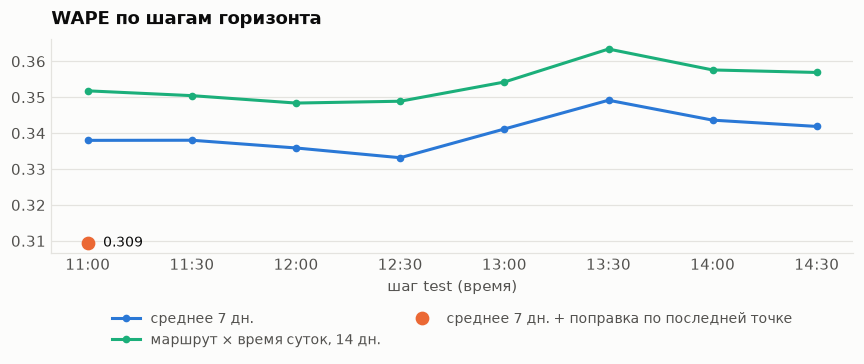

In [13]:
wape_h = pd.DataFrame({k: np.mean(v, 0) for k, v in per_h.items()}, index=range(1, H + 1))
fig, ax = plt.subplots(figsize=(8, 3.6))
for name, col in [('среднее 7 дн.', BLUE), ('маршрут × время суток, 14 дн.', AQUA)]:
    ax.plot(wape_h.index, wape_h[name], color=col, marker='o', markersize=4, label=name)
fix = wape_h['среднее 7 дн. + поправка 1-го шага'].iloc[0]
ax.plot([1], [fix], 'o', color=ORANGE, markersize=8, label='среднее 7 дн. + поправка по последней точке')
ax.annotate(f'{fix:.3f}', (1, fix), xytext=(10, 0), textcoords='offset points', va='center', color=INK, fontsize=9)
ax.set_xticks(range(1, H + 1), [f'{11 + (h - 1) // 2}:{"00" if h % 2 else "30"}' for h in range(1, H + 1)])
ax.set_title('WAPE по шагам горизонта'); ax.set_xlabel('шаг test (время)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=9)
plt.tight_layout()

- **Лучше всего работает среднее маршрута за последние 3–7 дней: WAPE ≈ 0.34.** Окно в 28 дней хуже — мешает тренд.
- Учёт времени суток не помогает (0.354): шум сильнее сезонности. «Последнее значение» — худший вариант (0.47).
- Поправка по последнему значению (`среднее + 0.48 × (последнее − среднее)`) улучшает **только первый шаг**: 0.338 → 0.309.

## 7. Выводы

1. **Главное — точно оценить текущий уровень маршрута** с учётом свежего тренда. Сезонность и прошлые значения дают мало.
2. Первые 1–2 шага можно уточнить по последнему значению и статусам на 10:30.
3. Планка для моделей — **WAPE 0.34**, проверять тем же способом, что в разделе 6.